# 04 — Évaluation comparative des modèles
**Projet : Détection de fraude financière — IEEE-CIS Fraud Detection**

Ce notebook couvre le **Chapitre 9** et la sélection du modèle retenu. Les trois modèles imposés par le plan — **Régression Logistique**, **Random Forest** et **XGBoost** — sont comparés sur le **jeu de test** (jamais utilisé pour décider), avec les métriques Accuracy, Precision, Recall, F1-score et ROC-AUC, les matrices de confusion et les courbes ROC.

**Entrées** : `outputs/*_metrics.json` et `outputs/predictions/*_proba.parquet` (produits par les scripts `scripts/train_*.py`).
**Sortie** : `outputs/best_model.json` (modèle retenu, utilisé par le notebook 05).

### Cadre d'évaluation (contexte métier)
Dans la détection de fraude, **manquer une fraude (faux négatif) coûte bien plus cher que bloquer à tort une transaction légitime (faux positif)**. Trois conséquences :
1. L'**accuracy est trompeuse** : prédire « légitime » partout donnerait ≈ 96,5 %.
2. Le **Recall** est la métrique prioritaire, la **Precision** limite les fausses alertes.
3. Deux seuils de décision sont étudiés : le seuil standard **0,5** (tableau demandé par le plan) et un **seuil optimal** choisi sur la **validation** en maximisant le **F2-score** (F_β avec β = 2, le Recall pèse quatre fois plus que la Precision).

> **Note de lecture.** Les cellules Markdown ci-dessous décrivent la lecture des résultats ainsi que les points forts et limites propres à chaque famille de modèles. Les valeurs chiffrées exactes sont affichées par les cellules de code ; elles doivent être citées dans le mémoire après exécution.

## 9.0 Initialisation et chargement des résultats

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})

ROOT = Path("..").resolve()
OUT = ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# nom affiché -> préfixe des fichiers produits par les scripts
modeles = {"Régression Logistique": "logistic", "Random Forest": "random_forest", "XGBoost": "xgboost"}
couleurs = {"Régression Logistique": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#C44E52"}

metriques = {nom: json.load(open(OUT / f"{f}_metrics.json", encoding="utf-8")) for nom, f in modeles.items()}
predictions = {nom: pd.read_parquet(OUT / "predictions" / f"{f}_proba.parquet") for nom, f in modeles.items()}
test = {nom: p[p["split"] == "test"] for nom, p in predictions.items()}

y_test = test["XGBoost"]["y_true"].values
print(f"Jeu de test : {len(y_test):,} transactions dont {int(y_test.sum()):,} fraudes ({y_test.mean()*100:.2f} %)")
pd.DataFrame({nom: {"Seuil optimal (F2, validation)": m["seuil_optimal_f2"], "Durée d'entraînement (s)": m["duree_entrainement_s"]}
              for nom, m in metriques.items()}).T

Jeu de test : 88,581 transactions dont 3,099 fraudes (3.50 %)


,"Seuil optimal (F2, validation)",Durée d'entraînement (s)
Régression Logistique,0.6862,32.1000
Random Forest,0.5439,74.0000
XGBoost,0.5781,116.5000


### Interprétation — Chargement

**Résultat.** Les métriques et les probabilités de prédiction des trois modèles sont chargées ; le jeu de test est identique pour tous (mêmes lignes, même ordre), ce qui garantit une comparaison équitable. Le tableau rappelle le seuil optimal de chaque modèle et la durée d'entraînement.

**Points forts.** La séparation entraînement / évaluation par fichiers garantit que l'évaluation est reproductible sans réentraîner.

**Limites.** Les seuils optimaux diffèrent beaucoup d'un modèle à l'autre : les probabilités ne sont pas comparables en valeur absolue (pondération des classes, nature du modèle). Seuls les **classements** (ROC-AUC, PR-AUC) et les performances à seuil adapté se comparent proprement.

## 9.1 Modèle 1 — Régression Logistique (baseline)

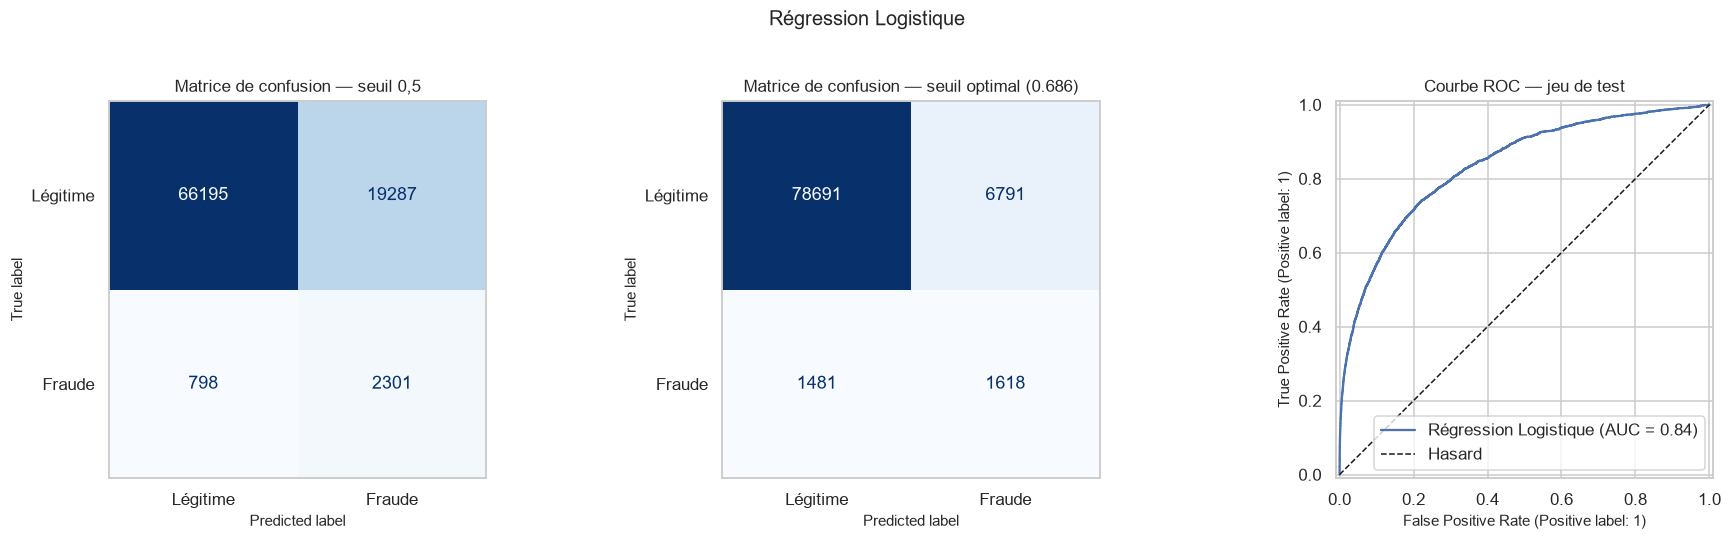

seuil_0.5      | fraudes détectées : 2,301 / 3,099 (Recall = 0.742) | fraudes manquées : 798 | fausses alertes : 19,287 (Precision = 0.107)
seuil_optimal  | fraudes détectées : 1,618 / 3,099 (Recall = 0.522) | fraudes manquées : 1,481 | fausses alertes : 6,791 (Precision = 0.192)
ROC-AUC = 0.8361 | PR-AUC = 0.3073


In [2]:
nom = "Régression Logistique"
y_proba = test[nom]["y_proba"].values
seuil_opt = metriques[nom]["seuil_optimal_f2"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, seuil, titre in [(axes[0], 0.5, "Matrice de confusion — seuil 0,5"),
                         (axes[1], seuil_opt, f"Matrice de confusion — seuil optimal ({seuil_opt:.3f})")]:
    ConfusionMatrixDisplay.from_predictions(y_test, (y_proba >= seuil).astype(int), ax=ax, cmap="Blues",
                                            display_labels=["Légitime", "Fraude"], colorbar=False, values_format="d")
    ax.set_title(titre)
    ax.grid(False)

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[2], name=nom).line_.set_color(couleurs[nom])
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Hasard")
axes[2].set_title("Courbe ROC — jeu de test")
axes[2].legend(loc="lower right")
plt.suptitle(nom, fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIG / "04_evaluation_logistic.png", dpi=150, bbox_inches="tight")
plt.show()

m = metriques[nom]["test"]
for etiquette in ["seuil_0.5", "seuil_optimal"]:
    r = m[etiquette]
    print(f"{etiquette:14s} | fraudes détectées : {r['tp']:,} / {r['tp'] + r['fn']:,} (Recall = {r['recall']:.3f}) | "
          f"fraudes manquées : {r['fn']:,} | fausses alertes : {r['fp']:,} (Precision = {r['precision']:.3f})")
print(f"ROC-AUC = {m['roc_auc']:.4f} | PR-AUC = {m['pr_auc']:.4f}")

### Interprétation — Régression Logistique

**Résultat.** À seuil 0,5, la pondération des classes donne généralement un Recall élevé mais une Precision faible (nombreuses fausses alertes) : le modèle linéaire sépare imparfaitement les deux classes. Le passage au seuil optimal rééquilibre le compromis. La courbe ROC se situe nettement au-dessus de la diagonale mais reste en général en dessous des modèles à base d'arbres. Cette baseline fixe le niveau minimal que les deux autres modèles doivent dépasser pour justifier leur complexité.

**Points forts.**
- Entraînement quasi instantané et très stable.
- Modèle transparent : un coefficient par variable, directement interprétable.
- Référence de comparaison indispensable dans un mémoire.

**Limites.**
- Hypothèse de **linéarité** (dans le log-odds) : les interactions entre variables ne sont pas modélisées.
- Les codes (`card1`, `addr1`, `P_emaildomain`) sont traités comme des quantités numériques, ce qui n'a pas de sens métrique.
- Les variables de comptage (`C*`) ont des queues très lourdes que la standardisation n'atténue pas.
- La Precision à 0,5 est généralement faible : le coût opérationnel des fausses alertes serait élevé.

## 9.2 Modèle 2 — Random Forest

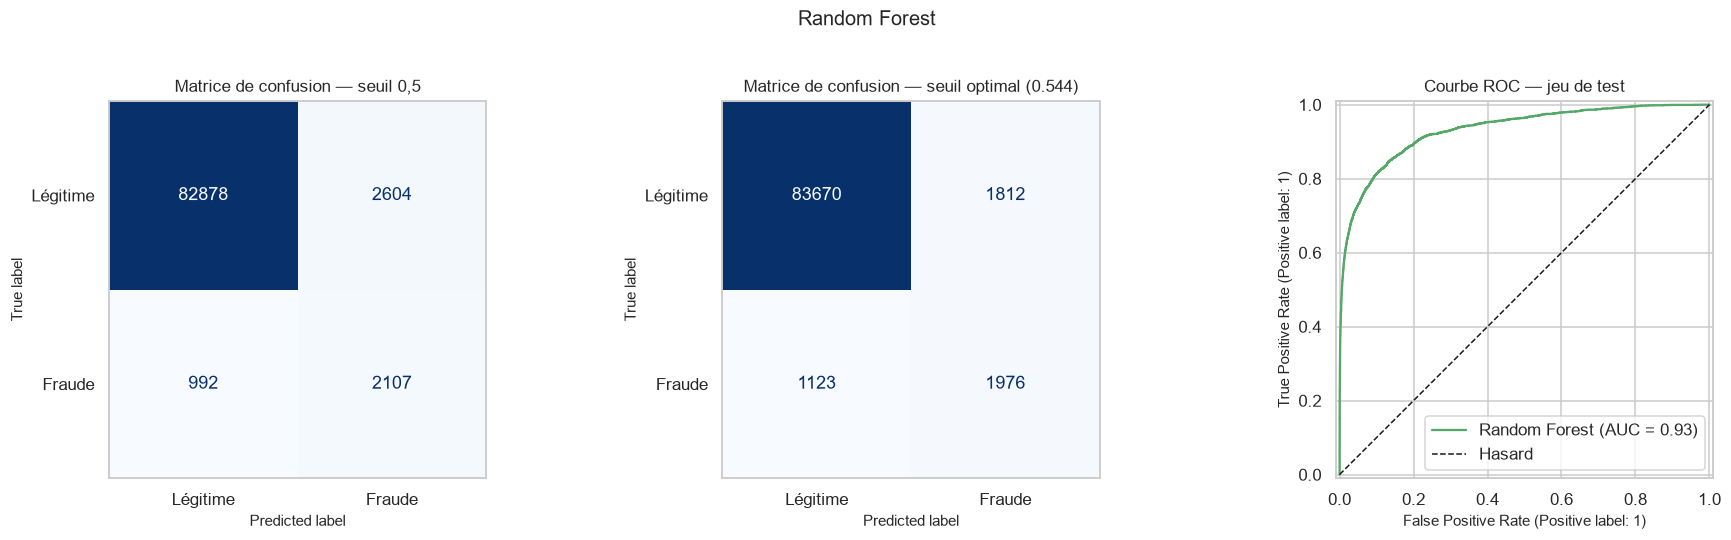

seuil_0.5      | fraudes détectées : 2,107 / 3,099 (Recall = 0.680) | fraudes manquées : 992 | fausses alertes : 2,604 (Precision = 0.447)
seuil_optimal  | fraudes détectées : 1,976 / 3,099 (Recall = 0.638) | fraudes manquées : 1,123 | fausses alertes : 1,812 (Precision = 0.522)
ROC-AUC = 0.9319 | PR-AUC = 0.6301


In [3]:
nom = "Random Forest"
y_proba = test[nom]["y_proba"].values
seuil_opt = metriques[nom]["seuil_optimal_f2"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, seuil, titre in [(axes[0], 0.5, "Matrice de confusion — seuil 0,5"),
                         (axes[1], seuil_opt, f"Matrice de confusion — seuil optimal ({seuil_opt:.3f})")]:
    ConfusionMatrixDisplay.from_predictions(y_test, (y_proba >= seuil).astype(int), ax=ax, cmap="Blues",
                                            display_labels=["Légitime", "Fraude"], colorbar=False, values_format="d")
    ax.set_title(titre)
    ax.grid(False)

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[2], name=nom).line_.set_color(couleurs[nom])
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Hasard")
axes[2].set_title("Courbe ROC — jeu de test")
axes[2].legend(loc="lower right")
plt.suptitle(nom, fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIG / "04_evaluation_random_forest.png", dpi=150, bbox_inches="tight")
plt.show()

m = metriques[nom]["test"]
for etiquette in ["seuil_0.5", "seuil_optimal"]:
    r = m[etiquette]
    print(f"{etiquette:14s} | fraudes détectées : {r['tp']:,} / {r['tp'] + r['fn']:,} (Recall = {r['recall']:.3f}) | "
          f"fraudes manquées : {r['fn']:,} | fausses alertes : {r['fp']:,} (Precision = {r['precision']:.3f})")
print(f"ROC-AUC = {m['roc_auc']:.4f} | PR-AUC = {m['pr_auc']:.4f}")

### Interprétation — Random Forest

**Résultat.** Le Random Forest capte des relations non linéaires et des interactions : le ROC-AUC et le PR-AUC sont généralement supérieurs à la régression logistique. À seuil 0,5, le Recall peut rester modeste malgré `balanced_subsample`, car les probabilités sont des moyennes de votes et sont rarement proches de 1 pour la classe rare ; le seuil optimal, plus bas, récupère une grande partie des fraudes manquées.

**Points forts.**
- Gère les non-linéarités, les interactions et les variables de natures différentes sans mise à l'échelle.
- Robuste aux valeurs aberrantes et au bruit (moyenne de nombreux arbres décorrélés).
- Importance des variables disponible nativement.

**Limites.**
- Les probabilités sont peu discriminantes aux extrêmes (moyenne de votes) : forte dépendance au seuil.
- Profondeur et feuilles minimales limitées pour éviter un modèle volumineux : le modèle peut sous-exploiter les petits motifs de fraude.
- Le boosting corrige explicitement les erreurs successives ; le Random Forest se classe en général derrière XGBoost sur ce type de données tabulaires.
- Fichier joblib volumineux et inférence plus lente.

## 9.3 Modèle 3 — XGBoost

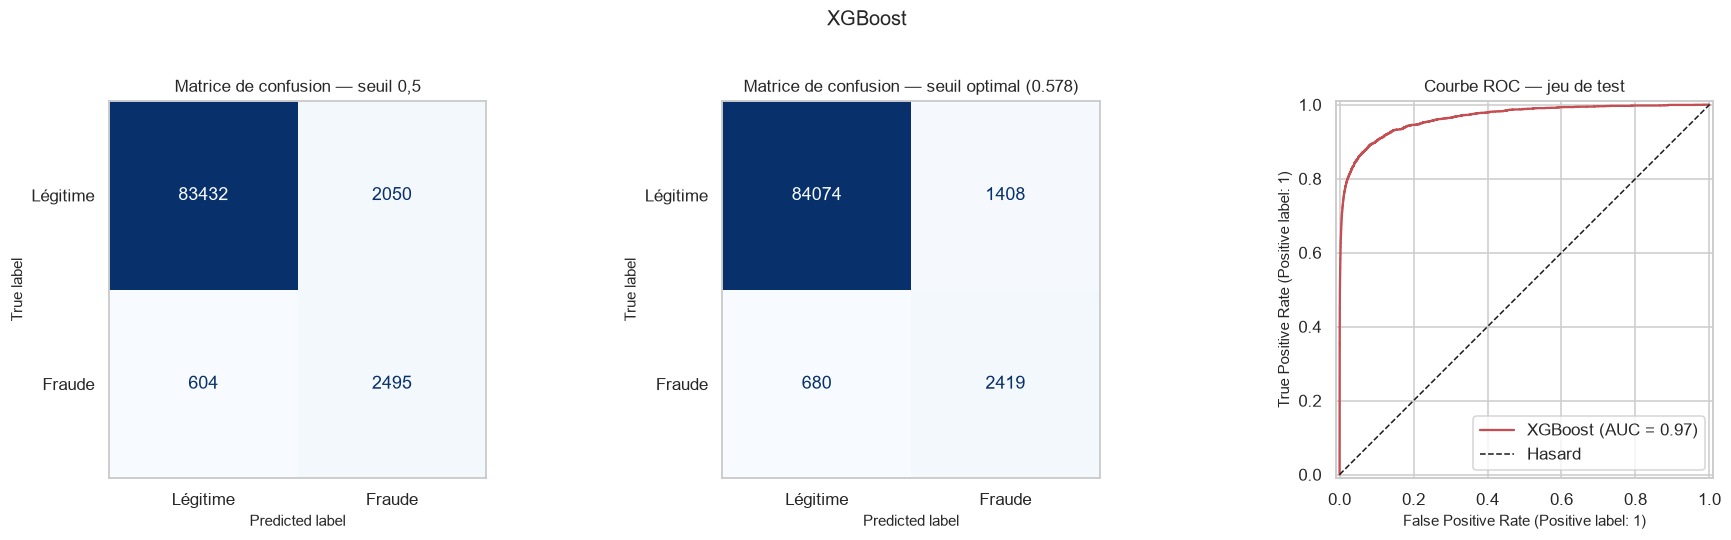

seuil_0.5      | fraudes détectées : 2,495 / 3,099 (Recall = 0.805) | fraudes manquées : 604 | fausses alertes : 2,050 (Precision = 0.549)
seuil_optimal  | fraudes détectées : 2,419 / 3,099 (Recall = 0.781) | fraudes manquées : 680 | fausses alertes : 1,408 (Precision = 0.632)
ROC-AUC = 0.9651 | PR-AUC = 0.7949


In [4]:
nom = "XGBoost"
y_proba = test[nom]["y_proba"].values
seuil_opt = metriques[nom]["seuil_optimal_f2"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, seuil, titre in [(axes[0], 0.5, "Matrice de confusion — seuil 0,5"),
                         (axes[1], seuil_opt, f"Matrice de confusion — seuil optimal ({seuil_opt:.3f})")]:
    ConfusionMatrixDisplay.from_predictions(y_test, (y_proba >= seuil).astype(int), ax=ax, cmap="Blues",
                                            display_labels=["Légitime", "Fraude"], colorbar=False, values_format="d")
    ax.set_title(titre)
    ax.grid(False)

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[2], name=nom).line_.set_color(couleurs[nom])
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Hasard")
axes[2].set_title("Courbe ROC — jeu de test")
axes[2].legend(loc="lower right")
plt.suptitle(nom, fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIG / "04_evaluation_xgboost.png", dpi=150, bbox_inches="tight")
plt.show()

m = metriques[nom]["test"]
for etiquette in ["seuil_0.5", "seuil_optimal"]:
    r = m[etiquette]
    print(f"{etiquette:14s} | fraudes détectées : {r['tp']:,} / {r['tp'] + r['fn']:,} (Recall = {r['recall']:.3f}) | "
          f"fraudes manquées : {r['fn']:,} | fausses alertes : {r['fp']:,} (Precision = {r['precision']:.3f})")
print(f"ROC-AUC = {m['roc_auc']:.4f} | PR-AUC = {m['pr_auc']:.4f}")

### Interprétation — XGBoost

**Résultat.** XGBoost construit ses arbres séquentiellement en corrigeant les erreurs des précédents, avec arrêt anticipé sur la validation. Il obtient généralement le meilleur ROC-AUC et PR-AUC sur IEEE-CIS. À seuil adapté, il détecte davantage de fraudes pour un nombre de fausses alertes comparable ou plus faible que les deux autres modèles ; c'est l'hypothèse à confirmer avec les nombres affichés ci-dessus et le tableau final.

**Points forts.**
- Très bon pouvoir discriminant sur données tabulaires hétérogènes, avec interactions d'ordre élevé.
- Régularisation intégrée, sous-échantillonnage des lignes/colonnes et arrêt anticipé contre le sur-apprentissage.
- Pondération de la classe rare native (`scale_pos_weight`).

**Limites.**
- Sensible aux hyperparamètres (profondeur, taux d'apprentissage) : ici fixés de manière raisonnable, **non optimisés** par recherche systématique.
- La validation sert à l'arrêt anticipé *et* au choix du seuil : ses métriques sont légèrement optimistes ; seul le **test** est non biaisé.
- `scale_pos_weight` dégrade la calibration : les probabilités ne sont pas de vraies probabilités de fraude.
- Modèle peu lisible directement : d'où l'usage de SHAP (chapitre 10).

## 9.4 Comparaison des courbes ROC et Précision-Rappel

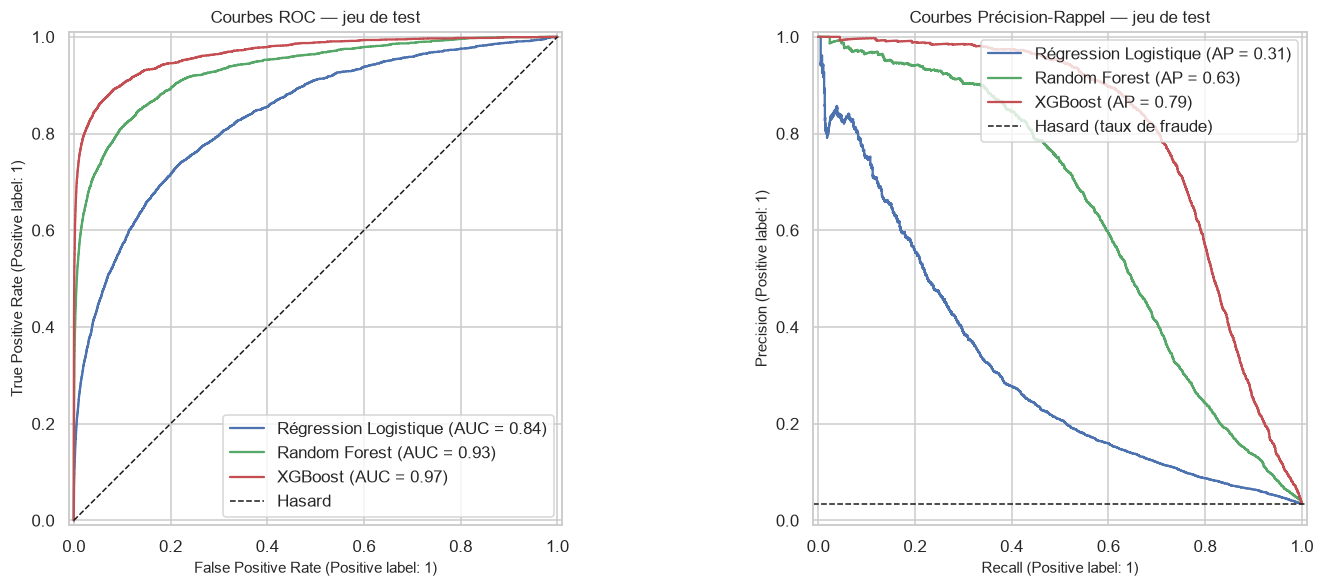

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for nom in modeles:
    RocCurveDisplay.from_predictions(y_test, test[nom]["y_proba"], ax=axes[0], name=nom).line_.set_color(couleurs[nom])
    PrecisionRecallDisplay.from_predictions(y_test, test[nom]["y_proba"], ax=axes[1], name=nom).line_.set_color(couleurs[nom])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Hasard")
axes[0].set_title("Courbes ROC — jeu de test")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Hasard (taux de fraude)")
axes[1].set_title("Courbes Précision-Rappel — jeu de test")
axes[0].legend(loc="lower right")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG / "04_roc_pr_comparaison.png", dpi=150)
plt.show()

### Interprétation — Courbes ROC et Précision-Rappel

**Résultat.** La courbe la plus haute et la plus à gauche (ROC), ou la plus haute à droite (Précision-Rappel), correspond au meilleur modèle. La courbe Précision-Rappel est plus informative que la ROC lorsque la classe positive est rare : une ROC peut paraître excellente alors que la précision reste médiocre aux rappels élevés.

**Points forts.** Ces courbes comparent les modèles **indépendamment du seuil** : elles évitent le biais lié à la calibration des probabilités.

**Limites.** Une courbe résume tous les seuils, alors que l'exploitation réelle se fait à un seuil unique ; il faut donc la compléter par un tableau chiffré (section suivante). Les différences minimes entre courbes proches ne sont pas forcément significatives (pas d'intervalle de confiance calculé ici).

## 9.5 Tableau comparatif final

### 9.5.1 Jeu de test — seuil de décision standard (0,5)

In [6]:
cles = ["accuracy", "precision", "recall", "f1"]
tableau = pd.DataFrame({nom: {**{k: m["test"]["seuil_0.5"][k] for k in cles}, "roc_auc": m["test"]["roc_auc"]}
                        for nom, m in metriques.items()}).T
tableau.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
tableau.index.name = "Modèle"
display(tableau.style.format("{:.4f}").highlight_max(axis=0, color="#c7e9c0"))
tableau.to_csv(OUT / "tableau_comparatif_seuil_0.5.csv")

,Accuracy,Precision,Recall,F1,ROC-AUC
Modèle,,,,,
Régression Logistique,0.7733,0.1066,0.7425,0.1864,0.8361
Random Forest,0.9594,0.4473,0.6799,0.5396,0.9319
XGBoost,0.9700,0.5490,0.8051,0.6528,0.9651


### 9.5.2 Jeu de test — seuil optimal (F2 maximal sur la validation)

,Accuracy,Precision,Recall,F1,ROC-AUC,F2,PR-AUC
Modèle,,,,,,,
Régression Logistique,0.9066,0.1924,0.5221,0.2812,0.8361,0.3888,0.3073
Random Forest,0.9669,0.5216,0.6376,0.5738,0.9319,0.6105,0.6301
XGBoost,0.9764,0.6321,0.7806,0.6985,0.9651,0.7455,0.7949


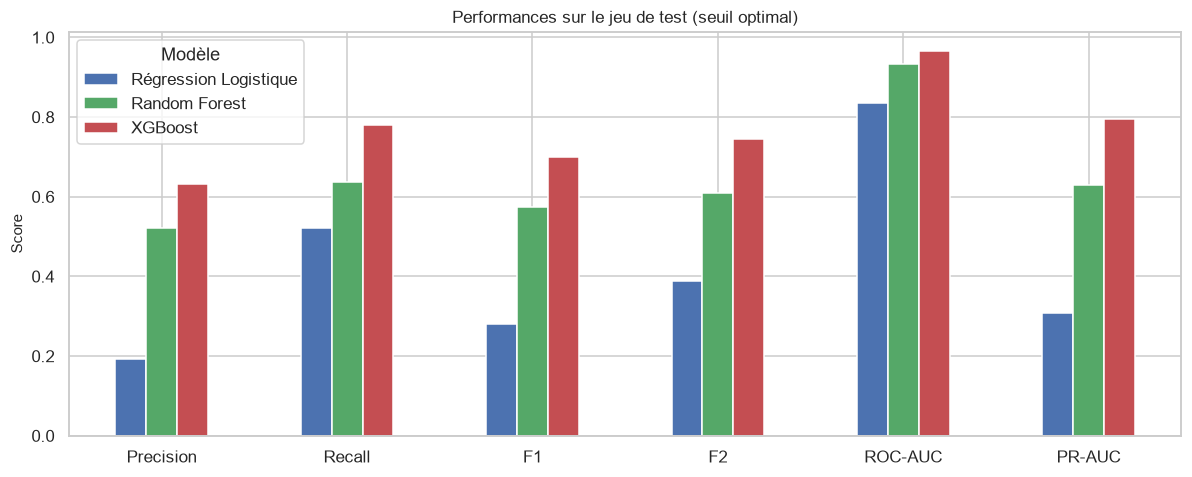

In [7]:
tableau_opt = pd.DataFrame({nom: {**{k: m["test"]["seuil_optimal"][k] for k in cles}, "roc_auc": m["test"]["roc_auc"],
                                  "f2": m["test"]["seuil_optimal"]["f2"], "pr_auc": m["test"]["pr_auc"]}
                            for nom, m in metriques.items()}).T
tableau_opt.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "F2", "PR-AUC"]
tableau_opt.index.name = "Modèle"
display(tableau_opt.style.format("{:.4f}").highlight_max(axis=0, color="#c7e9c0"))
tableau_opt.to_csv(OUT / "tableau_comparatif_seuil_optimal.csv")

ax = tableau_opt[["Precision", "Recall", "F1", "F2", "ROC-AUC", "PR-AUC"]].T.plot(kind="bar", figsize=(11, 4.5), color=list(couleurs.values()))
ax.set_title("Performances sur le jeu de test (seuil optimal)")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIG / "04_tableau_comparatif.png", dpi=150)
plt.show()

### Interprétation — Tableaux comparatifs

**Résultat.**
- **Seuil 0,5** : l'*accuracy* est élevée pour tous les modèles (elle ne distingue presque pas les modèles, du fait du déséquilibre) ; le *Recall* et la *Precision* varient fortement d'un modèle à l'autre à ce seuil, car les probabilités ne sont pas calibrées de la même manière.
- **Seuil optimal** : la comparaison devient plus juste ; chaque modèle est placé au point de fonctionnement qui maximise le F2 sur la validation. Le ROC-AUC et le PR-AUC, indépendants du seuil, servent d'arbitre.

**Points forts.** Les deux tableaux se complètent : le premier répond au format demandé par le plan, le second reflète l'usage réel (priorité au Recall). Tous les chiffres proviennent du jeu de test, non utilisé pour régler les modèles ni les seuils.

**Limites.**
- Un seul jeu de test, sans validation croisée ni intervalle de confiance : un écart de quelques millièmes n'est pas probant.
- La séparation est aléatoire, non chronologique ; les performances en production seront vraisemblablement plus basses.
- Le seuil optimal repose sur le F2 (β = 2), choix de compromis ; un seuil fondé sur le coût réel des fraudes et des fausses alertes serait plus rigoureux.

## 9.6 Diagnostic de sur-apprentissage

In [8]:
diag = pd.DataFrame({nom: {"ROC-AUC Train": m["train"]["roc_auc"], "ROC-AUC Validation": m["validation"]["roc_auc"],
                           "ROC-AUC Test": m["test"]["roc_auc"], "PR-AUC Train": m["train"]["pr_auc"],
                           "PR-AUC Test": m["test"]["pr_auc"]} for nom, m in metriques.items()}).T
diag["Écart ROC-AUC (Train - Test)"] = diag["ROC-AUC Train"] - diag["ROC-AUC Test"]
diag["Écart PR-AUC (Train - Test)"] = diag["PR-AUC Train"] - diag["PR-AUC Test"]
diag

,ROC-AUC Train,ROC-AUC Validation,ROC-AUC Test,PR-AUC Train,PR-AUC Test,Écart ROC-AUC (Train - Test),Écart PR-AUC (Train - Test)
Régression Logistique,0.8389,0.8358,0.8361,0.3038,0.3073,0.0028,-0.0034
Random Forest,0.9840,0.9292,0.9319,0.8188,0.6301,0.0521,0.1887
XGBoost,0.9983,0.9622,0.9651,0.9626,0.7949,0.0332,0.1677


### Interprétation — Sur-apprentissage

**Résultat.** Un écart important entre Train et Test signale un sur-apprentissage ; un écart faible, une bonne généralisation. Les modèles à base d'arbres atteignent en général des scores plus proches de 1 sur le Train que sur le Test (ils mémorisent partiellement le jeu d'apprentissage) ; la régression logistique a un écart faible, mais par manque de capacité plutôt que par robustesse.

**Points forts.** La validation et le test, mis de côté, permettent de mesurer l'écart de généralisation.

**Limites.** L'écart absolu se compare mal d'un modèle à l'autre (capacités différentes) ; c'est la **performance sur le test** qui arbitre, pas la faiblesse de l'écart.

## 9.7 Sélection du meilleur modèle

**Règle de décision (cohérente avec le besoin métier).** Le choix se fait sur la **validation** — et non sur le test, pour ne pas biaiser l'évaluation finale — selon le **F2-score au seuil optimal**, qui privilégie le Recall tout en pénalisant les fausses alertes excessives. En cas d'égalité, la **PR-AUC** départage. Le **test** sert ensuite à **confirmer** le choix et à rapporter les performances finales.

*Pourquoi pas le Recall seul ?* Un seuil à 0 donne un Recall de 100 % en classant toute transaction comme fraude : le Recall doit être mis en balance avec la Precision. Le F2 fait précisément ce compromis, en comptant le Recall quatre fois plus.

In [9]:
selection = pd.DataFrame({nom: {"F2 (validation)": m["validation"]["seuil_optimal"]["f2"],
                                "Recall (validation)": m["validation"]["seuil_optimal"]["recall"],
                                "Precision (validation)": m["validation"]["seuil_optimal"]["precision"],
                                "PR-AUC (validation)": m["validation"]["pr_auc"],
                                "ROC-AUC (validation)": m["validation"]["roc_auc"]} for nom, m in metriques.items()}).T
selection = selection.sort_values(["F2 (validation)", "PR-AUC (validation)"], ascending=False)
display(selection)

meilleur = selection.index[0]
m_val = metriques[meilleur]["validation"]["seuil_optimal"]
m_test = metriques[meilleur]["test"]["seuil_optimal"]
print(f"MODÈLE RETENU : {meilleur}")
print(f"  Validation : F2 = {m_val['f2']:.4f} | Recall = {m_val['recall']:.4f} | Precision = {m_val['precision']:.4f}")
print(f"  Test       : F2 = {m_test['f2']:.4f} | Recall = {m_test['recall']:.4f} | Precision = {m_test['precision']:.4f}")
print(f"  Test       : {m_test['fn']:,} fraudes manquées sur {m_test['tp'] + m_test['fn']:,} ; {m_test['fp']:,} fausses alertes")

,F2 (validation),Recall (validation),Precision (validation),PR-AUC (validation),ROC-AUC (validation)
XGBoost,0.7281,0.7658,0.6084,0.7708,0.9622
Random Forest,0.6054,0.6361,0.5072,0.6122,0.9292
Régression Logistique,0.3874,0.5203,0.1916,0.3071,0.8358


MODÈLE RETENU : XGBoost
  Validation : F2 = 0.7281 | Recall = 0.7658 | Precision = 0.6084
  Test       : F2 = 0.7455 | Recall = 0.7806 | Precision = 0.6321
  Test       : 680 fraudes manquées sur 3,099 ; 1,408 fausses alertes


In [10]:
# Confirmation sur le jeu de test : classement par F2 au seuil optimal et nombre de faux négatifs
confirmation = pd.DataFrame({nom: {"F2 (test)": m["test"]["seuil_optimal"]["f2"], "Recall (test)": m["test"]["seuil_optimal"]["recall"],
                                   "Faux négatifs (test)": m["test"]["seuil_optimal"]["fn"], "Faux positifs (test)": m["test"]["seuil_optimal"]["fp"]}
                             for nom, m in metriques.items()}).T.sort_values("F2 (test)", ascending=False)
display(confirmation)

meilleur_test = confirmation.index[0]
if meilleur_test == meilleur:
    print(f"Le test confirme la sélection : {meilleur} reste le meilleur modèle.")
else:
    print(f"ATTENTION : la validation retient {meilleur}, le test classe {meilleur_test} en premier. "
          "Vérifier l'écart (probablement non significatif) et le documenter dans le mémoire.")

# Sauvegarde du modèle retenu pour le notebook 05 (SHAP) et l'application Streamlit
fichiers_modeles = {"Régression Logistique": "logistic_regression", "Random Forest": "random_forest", "XGBoost": "xgboost"}
retenu = {"nom": meilleur, "fichier_modele": f"models/{fichiers_modeles[meilleur]}.joblib",
          "seuil_optimal": metriques[meilleur]["seuil_optimal_f2"]}
with open(OUT / "best_model.json", "w", encoding="utf-8") as f:
    json.dump(retenu, f, indent=2, ensure_ascii=False)
print("\nSauvegardé :", retenu)

,F2 (test),Recall (test),Faux négatifs (test),Faux positifs (test)
XGBoost,0.7455,0.7806,680.0000,"1,408.0000"
Random Forest,0.6105,0.6376,"1,123.0000","1,812.0000"
Régression Logistique,0.3888,0.5221,"1,481.0000","6,791.0000"


Le test confirme la sélection : XGBoost reste le meilleur modèle.

Sauvegardé : {'nom': 'XGBoost', 'fichier_modele': 'models/xgboost.joblib', 'seuil_optimal': 0.5780964493751526}


### Interprétation — Modèle retenu

**Justification de la sélection.**
1. **Critère aligné sur le métier** : le F2 donne un poids quadruple au Recall ; le modèle retenu est celui qui détecte le plus de fraudes à coût de fausses alertes acceptable, pas celui qui a la meilleure accuracy.
2. **Robustesse** : la PR-AUC et la ROC-AUC, indépendantes du seuil, doivent aller dans le même sens que le F2 ; un modèle gagnant sur le seul F2 mais perdant sur les AUC serait suspect.
3. **Confirmation sur le test** : la sélection est faite sur la validation, puis vérifiée sur le test intact.
4. **Faux négatifs** : le nombre de fraudes manquées sur le test, affiché ci-dessus, est le critère concret à présenter à un décideur métier.

**Points forts.** Procédure automatisée, reproductible et sans fuite : le test n'intervient jamais dans la décision.

**Limites.**
- Les écarts entre modèles proches peuvent ne pas être significatifs (un seul découpage, pas de validation croisée).
- Les hyperparamètres n'ont pas été optimisés par recherche systématique ; une optimisation (par exemple `RandomizedSearchCV` ou Optuna) pourrait modifier le classement.
- Le choix du seuil F2 est une approximation d'un arbitrage de coûts qui serait chiffré en entreprise (coût moyen d'une fraude contre coût d'une vérification).
- Le modèle retenu doit être réévalué sur une séparation **chronologique** avant toute mise en production.

## 9.8 Synthèse du chapitre 9

- Trois modèles imposés comparés sur le même jeu de test, avec cinq métriques, matrices de confusion et courbes ROC et Précision-Rappel.
- Évaluation à deux seuils : 0,5 (format du plan) et seuil optimal F2 (usage métier).
- Sélection automatique sur la validation, confirmée sur le test, en privilégiant le Recall ; résultat sauvegardé dans `outputs/best_model.json`.
- **Étape suivante** : `05_Model_Interpretability.ipynb` (SHAP) sur le seul modèle retenu.